### Bradley Terry Model

Here, the Bradley Terry model using the choix library... but as the choix library is using something called i slr algorithm, 

In [1]:
pip install choix


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


firstly importing the dependencies..

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import choix
# %matplotlib inline .. # (only if you're implementing it via jupyyter notebook..)
np.random.seed(42) # so everytime the seed pins the starting point of the generator..
import pandas as pd


Here I have taken the same 5 real-world commute options from IIT Madras → Airport as in the overleaf (Page no 1)
 And the true underlying "strengths" of each item (log-space parameters)..which is the goal of trying to recover it from the MLE from the comparison data... 



In [ ]:
items = ["Car", "Taxi", "Bike", "Bus", "Walking"]
n_items = len(items)
true_weights = np.array([0.40, 0.25, 0.15, 0.12, 0.08]) # weights taken same as the notes..
true_params = np.log(true_weights)

Here I am Centering them.. shift-invariance / identifiability constraint (overleaf page no. 2 & 3)

In [4]:
true_params = true_params - np.mean(true_params)
print("Items:       ", items)
print("True weights:", true_weights)
print("True params: ", np.round(true_params, 3))

Items:        ['Car', 'Taxi', 'Bike', 'Bus', 'Walking']
True weights: [0.4  0.25 0.15 0.12 0.08]
True params:  [ 0.853  0.383 -0.128 -0.351 -0.757]


So before this.. what do we have and what we are finding out..?
so, let us consider that we are standing outside iitm gate and then asking like roughly 20000 people about the choices between the commutes option
like car v/s bike or bike v/s walking and so on
now at the end we get the data..
Car beat Taxi
Taxi beat Bike
Car beat Bus
Walking lost to Bike
...
(20000 rows)

 *and now from the pile of this winner and loosers we are trying to find it out that how MUCH the people liked car over bike and all.. like the real true strength*



##### That is what we will try to to in real life but as of now in this notebook the objective is to pretend that we don't know the strength (which we have generated) and we try to figure out the real data as in the hidden strength and then we try to match it out as well

In [ ]:
# Number of pairwise comparisons to simulate (like asking 2000 people)
n_comparisons = 2000
data = []
for _ in range(n_comparisons):
    i, j = np.random.choice(n_items, size=2, replace=False)
    prob_i_wins = np.exp(true_params[i]) / (np.exp(true_params[i]) + np.exp(true_params[j]))
    if np.random.rand() < prob_i_wins:
        data.append((i, j))   # i wins, j loses
    else:
        data.append((j, i))   # j wins, i loses
print(f"Generated {len(data)} pairwise comparisons")
print(f"First 5 comparisons (winner_idx, loser_idx): {data[:5]}")
print(f"Example decoded: '{items[data[0][0]]}' beat '{items[data[0][1]]}'")

Generated 2000 pairwise comparisons
First 5 comparisons (winner_idx, loser_idx): [(4, 1), (3, 0), (4, 1), (3, 4), (4, 2)]
Example decoded: 'Walking' beat 'Taxi'


Quick EDA of Generated Comparisons.. 

In [9]:
data_arr = np.array(data)
wins = np.bincount(data_arr[:, 0], minlength=n_items)
appearances = np.bincount(data_arr.flatten(), minlength=n_items)
win_rate = wins / appearances

print(f"{'Item':<10}{'Wins':>6}{'Appearances':>14}{'Win Rate':>12}{'True Weight':>14}")
print("-" * 56)
for idx, name in enumerate(items):
    print(f"{name:<10}{wins[idx]:>6}{appearances[idx]:>14}"
          f"{win_rate[idx]:>12.3f}{true_weights[idx]:>14.3f}")

Item        Wins   Appearances    Win Rate   True Weight
--------------------------------------------------------
Car          592           811       0.730         0.400
Taxi         513           810       0.633         0.250
Bike         372           810       0.459         0.150
Bus          293           773       0.379         0.120
Walking      230           796       0.289         0.080


Now, fitting the bradley terry via mle using choix..
choix.ilsr_pairwise runs the I-LSR algorithm (Iterative Luce Spectral Ranking)


In [10]:
estimated_params = choix.ilsr_pairwise(
    n_items=n_items,
    data=data,
    alpha=0.01   # small regularization to keep numerics stable
)

print("True parameters:     ", np.round(true_params, 3))
print("Estimated parameters:", np.round(estimated_params, 3))
print()
print(f"Sum of estimated params: {estimated_params.sum():.6f}   (should be ~0)")

True parameters:      [ 0.853  0.383 -0.128 -0.351 -0.757]
Estimated parameters: [ 0.827  0.461 -0.122 -0.418 -0.749]

Sum of estimated params: -0.000000   (should be ~0)


Now, visualizing the true v/s estimated paramteters

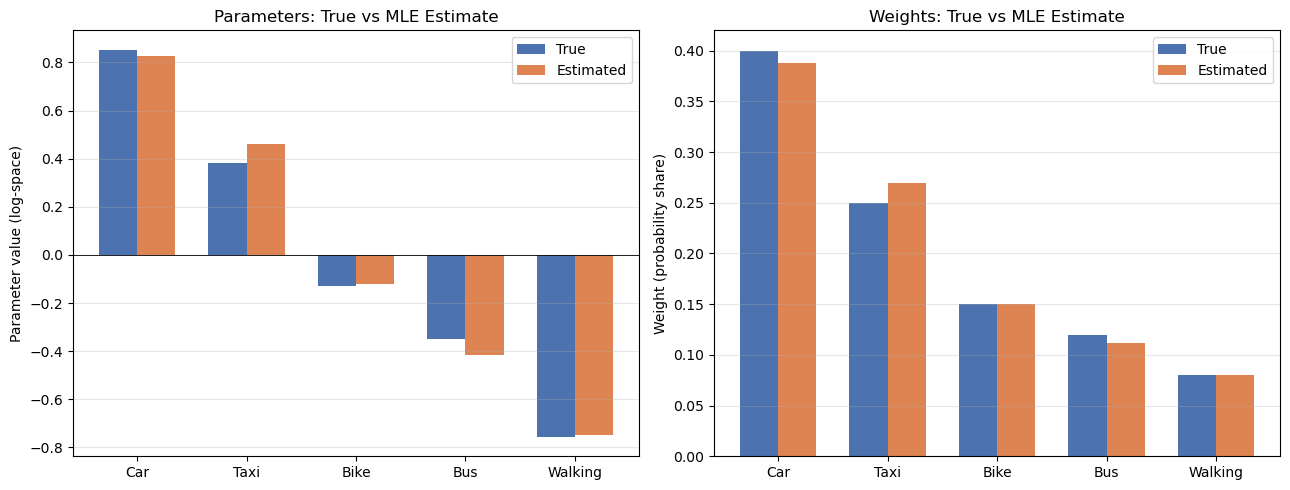

Mean absolute error on parameters: 0.0370
Mean absolute error on weights:    0.0080


In [11]:
# Convert estimated params back to weights (for the second subplot)
# weight = exp(param), then normalize so they sum to 1
estimated_weights = np.exp(estimated_params)
estimated_weights = estimated_weights / estimated_weights.sum()

# Set up side-by-side plots: parameters on the left, weights on the right
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.arange(n_items)
bar_width = 0.35

# --- Left plot: True vs Estimated PARAMETERS (log-space) ---
axes[0].bar(x - bar_width/2, true_params,      bar_width, label="True",      color="#4C72B0")
axes[0].bar(x + bar_width/2, estimated_params, bar_width, label="Estimated", color="#DD8452")
axes[0].axhline(0, color="black", linewidth=0.6)
axes[0].set_xticks(x)
axes[0].set_xticklabels(items)
axes[0].set_ylabel("Parameter value (log-space)")
axes[0].set_title("Parameters: True vs MLE Estimate")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# --- Right plot: True vs Estimated WEIGHTS (probability-space) ---
axes[1].bar(x - bar_width/2, true_weights,      bar_width, label="True",      color="#4C72B0")
axes[1].bar(x + bar_width/2, estimated_weights, bar_width, label="Estimated", color="#DD8452")
axes[1].set_xticks(x)
axes[1].set_xticklabels(items)
axes[1].set_ylabel("Weight (probability share)")
axes[1].set_title("Weights: True vs MLE Estimate")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Quantify the recovery — mean absolute error on both scales
param_mae  = np.mean(np.abs(true_params  - estimated_params))
weight_mae = np.mean(np.abs(true_weights - estimated_weights))

print(f"Mean absolute error on parameters: {param_mae:.4f}")
print(f"Mean absolute error on weights:    {weight_mae:.4f}")

here, bradley terry via gradient descent

True parameters:            [ 0.853  0.383 -0.128 -0.351 -0.757]
choix I-LSR:                [ 0.827  0.461 -0.122 -0.418 -0.749]
Gradient descent (scratch): [ 0.537  0.309 -0.088 -0.273 -0.486]

MAE (GD vs true):  0.15570
MAE (GD vs choix): 0.17668


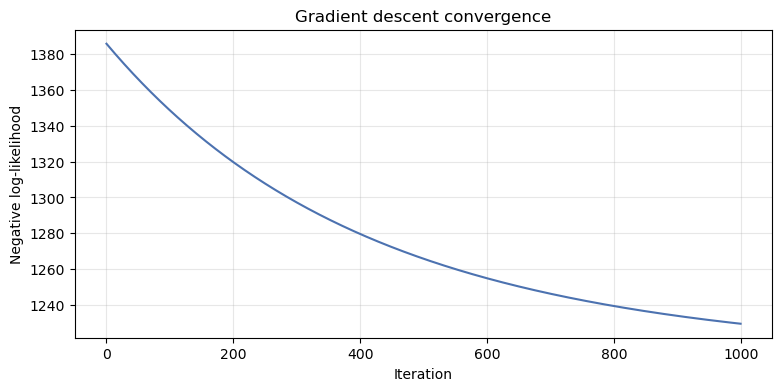

In [ ]:
data_arr = np.array(data)
winners = data_arr[:, 0]   
losers  = data_arr[:, 1]   


def sigmoid(x):
    """Numerically stable sigmoid — never overflows for large |x|."""
    return np.where(x >= 0,
                    1.0 / (1.0 + np.exp(-x)),
                    np.exp(x) / (1.0 + np.exp(x)))

def neg_log_likelihood(params):
    """Negative log-likelihood of the Bradley-Terry model.
    We minimize this = maximize log-likelihood."""
    diff = params[winners] - params[losers]      
    return np.sum(np.log1p(np.exp(-diff)))        


def gradient_of_nll(params):
    p_winner_wins = sigmoid(params[winners] - params[losers])
    residual = 1.0 - p_winner_wins
    
    grad = np.zeros(n_items)
    np.add.at(grad, winners, -residual)
    np.add.at(grad, losers,   residual)
    return grad / len(winners)      
params_gd     = np.zeros(n_items)   
learning_rate = 0.01
n_iterations  = 1000

nll_history = []

for step in range(n_iterations):
    g = gradient_of_nll(params_gd)
    params_gd = params_gd - learning_rate * g
    

    params_gd = params_gd - np.mean(params_gd)
    
    nll_history.append(neg_log_likelihood(params_gd))
print(f"True parameters:            {np.round(true_params,      3)}")
print(f"choix I-LSR:                {np.round(estimated_params, 3)}")
print(f"Gradient descent (scratch): {np.round(params_gd,        3)}")
print()
print(f"MAE (GD vs true):  {np.mean(np.abs(params_gd - true_params)):.5f}")
print(f"MAE (GD vs choix): {np.mean(np.abs(params_gd - estimated_params)):.5f}")
plt.figure(figsize=(9, 4))
plt.plot(nll_history, color="#4C72B0")
plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("Gradient descent convergence")
plt.grid(alpha=0.3)
plt.show()